In [2]:
import networkx as nx
import random
import matplotlib.pyplot as plt

from itertools import combinations

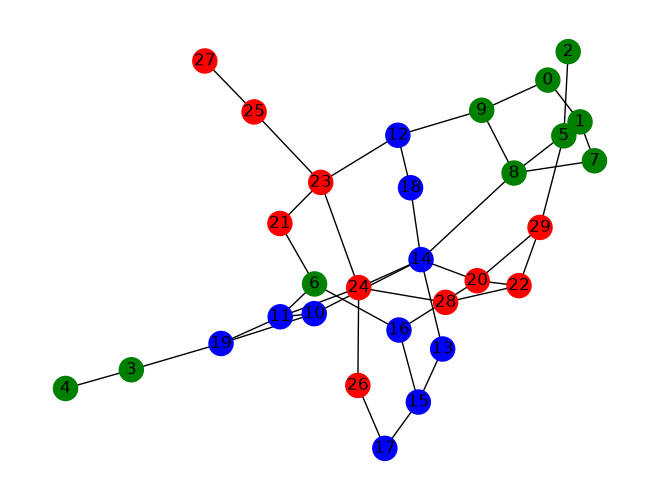

In [43]:
#code block for Exercise 1
def SBM(c, nc, p_intra, p_inter):
  #add your code here that implements SBM model as mentioned in homework Exercise 1.
  nodes = range(0, nc*c)
  groups = []
  for ci in range(c):
    groups += [ci] * nc

  G = nx.Graph()
  for node, group in zip(nodes, groups):
    G.add_node(node, group=group)

  for node1, node2 in combinations(nodes, 2):

    random_val = random.random()
    if G.nodes[node1]["group"] == G.nodes[node2]["group"]:
      if random_val < p_intra:
        G.add_edge(node1, node2)
    else:
      if random_val < p_inter:
        G.add_edge(node1, node2)

  return G

#this will create the example network to be added in the report
def plot_SBM_example_network():
  G=SBM(3, 10, 0.2, 0.05)

  color_map = {0 : "green",
               1 : "blue",
               2 : "red"}
  colors = [color_map[G.nodes[node]["group"]] for node in G.nodes]

  nx.draw(
      G, 
      node_color=colors, 
      with_labels=True
      )
  plt.show()
  #write down the code to plot the network as mentioned in the exercise

plot_SBM_example_network()
G1=SBM(10, 100, 0.1, 0.01)

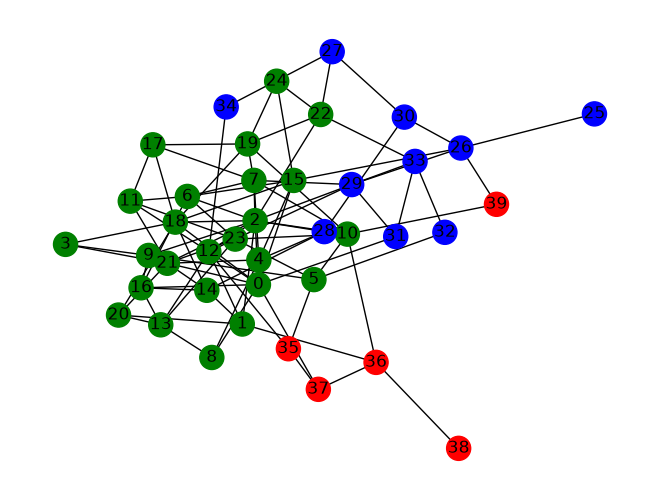

In [44]:
#code block for Exercise 2
def SBM_D(comm_size, p_intra, p_inter):

  # Create nodes
  nodes = []
  n = 0
  for s in comm_size:
    nodes += range(n, n+s)
    n += s

  # Create node group labels
  groups = []
  for ci in range(len(comm_size)):
    groups += [ci] * comm_size[ci]

  # Add nodes to graph
  G = nx.Graph()
  for node, group in zip(nodes, groups):
    G.add_node(node, group=group)

  # Create edges between node pairs
  for node1, node2 in combinations(nodes, 2):

    random_val = random.random()
    if G.nodes[node1]["group"] == G.nodes[node2]["group"]: # Use intra prob if group label is the same
      if random_val < p_intra:
        G.add_edge(node1, node2)
    else:
      if random_val < p_inter:
        G.add_edge(node1, node2)

  return G
#this will create the example network to be added in the report
def plot_SBM_D_example_network():
  G=SBM_D([25, 10, 5], 0.2, 0.05)

  color_map = {0 : "green",
               1 : "blue",
               2 : "red"}
  colors = [color_map[G.nodes[node]["group"]] for node in G.nodes]

  nx.draw(
      G, 
      node_color=colors, 
      with_labels=True
      )
  plt.show()
  #write down the code to plot the network as mentioned in the exercise

plot_SBM_D_example_network()
G2=SBM_D([500, 200, 100, 100, 100], 0.1, 0.01)
G3=SBM_D([600, 200, 100, 50, 50], 0.1, 0.01)

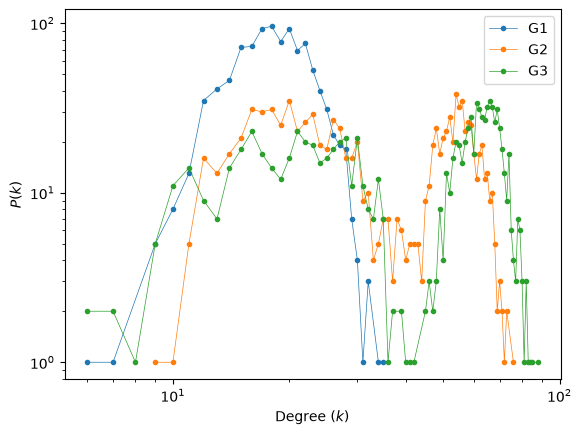

In [ ]:
#code block for Exercise 3
def degree_distribution(G1, G2, G3):
  def sort_degree_dist(G):
    degree_counts = {}
    total = 0
    for _, deg in sorted(G.degree, key=lambda x: x[1]):
      if deg in degree_counts:
        degree_counts[deg] += 1
      else:
        degree_counts[deg] = 1 
      total += 1

    x = sorted(degree_counts.keys())
    y = [degree_counts[xi] / total for xi in x]
    
    return x, y

  labels = {G1 : "G1",
            G2 : "G2",
            G3 : "G3"}
  for g in [G1, G2, G3]:
    gx, gy = sort_degree_dist(g)
    plt.plot(gx, gy, label=labels[g], linewidth=0.5, marker='o', markersize=3)

  plt.legend()
  plt.xscale("log")
  plt.yscale("log")
  plt.xlabel(r"Degree ($k$)")
  plt.ylabel(r"$P(k)$")

  plt.show()
#here we call the implemented function to plot degree distribution
degree_distribution(G1, G2, G3)

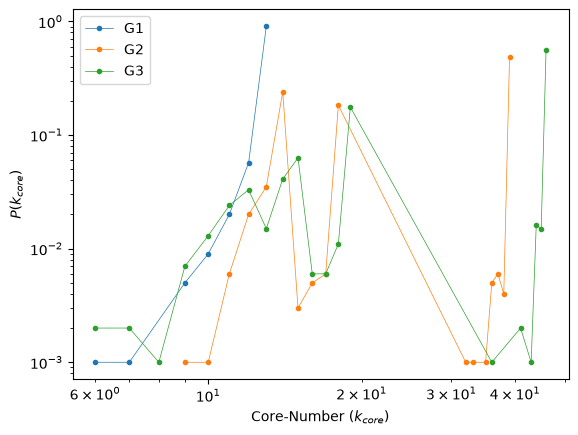

In [70]:
#code block for Exercise 4
def core_number_distribution(G1, G2, G3):
  def sort_core_dist(G):
    core_counts = {}
    total = 0
    for _, c in sorted(nx.core_number(G).items(), key=lambda x: x[1]):
      if c in core_counts:
        core_counts[c] += 1
      else:
        core_counts[c] = 1 
      total += 1

    x = sorted(core_counts.keys())
    y = [core_counts[xi] / total for xi in x]
    
    return x, y

  labels = {G1 : "G1",
            G2 : "G2",
            G3 : "G3"}
  for g in [G1, G2, G3]:
    gx, gy = sort_core_dist(g)
    plt.plot(gx, gy, label=labels[g], linewidth=0.5, marker='o', markersize=3)

  plt.legend()
  plt.xscale("log")
  plt.yscale("log")
  plt.xlabel(r"Core-Number ($k_{core}$)")
  plt.ylabel(r"$P(k_{core})$")

  plt.show()

#here we call the implemented function to plot core-number distribution
core_number_distribution(G1, G2, G3)